In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xobjects as xo
import xtrack as xt
import xpart as xp
import sys
import xplt

sys.path.append('/mnt/c/muco/code')
from rcsparameters.geometry.geometry import Geometry, load_file
from rcsparameters.geometry.cell import Cell
from generate_fodo import fodo, plot_twiss, apert_1b_optics, apert_2b_optics,size_beam_diam_hor, plot_path_diff,size_beam_diam_vert,vert_apert
# from ramping_module import ramping
# from track_function import track
import json

plt.rc('axes', labelsize=12)     # fontsize of the x and y labels
plt.rc('xtick', labelsize=11)    # fontsize of the tick labels
plt.rc('ytick', labelsize=11)    # fontsize of the tick labels
plt.rc('legend', fontsize=12)    # legend fontsize

/mnt/c/muco/test_venv/lib/python3.11/site-packages/numpy/_core/getlimits.py:545: UserWarning: Signature b'\x00\xd0\xcc\xcc\xcc\xcc\xcc\xcc\xfb\xbf\x00\x00\x00\x00\x00\x00' for <class 'numpy.longdouble'> does not match any known type: falling back to type probe function.
This warnings indicates broken support for the dtype!
  machar = _get_machar(dtype)


Define geometry

In [2]:
file_input='/mnt/c/muco/code/class_geometry/parameter_files/para_RCS_HE.txt'
kw_geo=load_file(file_input)
default_para_RCS1={
        'n_sigma':6, #Nb of sigma of beam size that the QP aperture must fit
        'sigma_delta':5e-3, #Max dispersion in energy of the beam
        'emitt_n':25e-6, #Normalized emittance
        'n_cav':540, #Total number of cavity : 700, 380, 540, 3000 
        'l_cav':1.2474, #Length of 1 cavity
        'mu':np.pi/2, #Phase advance per cell
        'apert_min':30e-3, #Min aperture size (diam) to be taken for QP
        'dx':10e-3, #Extra radius length to be taken to fit vacuum chambers
        'Bpole':1, #Max field on QP pole
    }
rcs = Cell(file_input_geo=kw_geo,file_input_opt=default_para_RCS1)
time=0
n_slice=0
option='var_ref'
L_sxt=1
n_turn_rcs=66
print(rcs.nb_cell_arc)

Load json file /mnt/c/muco/code/class_geometry/parameter_files/para_RCS_HE.txt
1 bloc
geo
6.0


/mnt/c/muco/mhega/rcsparameters/rcsparameters/geometry/geometry.py:299: UserWarning: Number of cells per arc was optimised from 17 to 13
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)
/mnt/c/muco/mhega/rcsparameters/rcsparameters/geometry/geometry.py:299: UserWarning: Number of cells per arc was optimised from 13 to 9
  warnings.warn(f"Number of cells per arc was optimised from {self._nb_cell_arc} to {self.nc_best}", UserWarning)


Equivalent FODO cell

Repetition found in `element_names` -> renaming


Extra per quad: 0.2622073548883382
Total insertion length 58.79120879120878


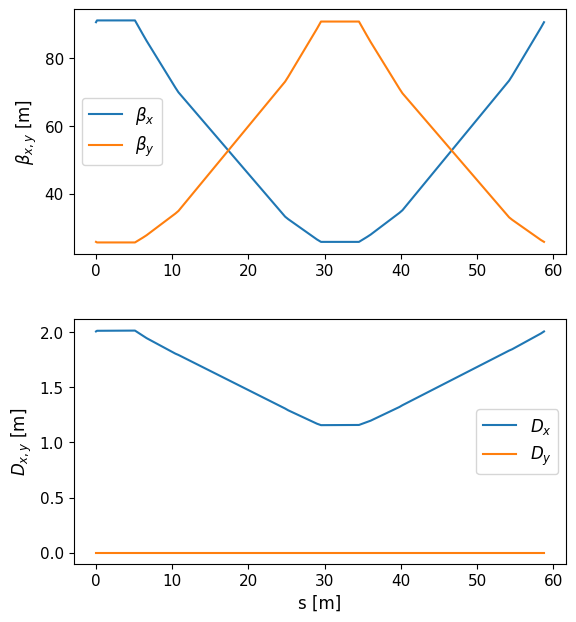

In [3]:
FODO_el, FODO_names, arc_el, arc_names=fodo(RCS=rcs, n_turn_rcs=n_turn_rcs, length_sxt=L_sxt, time_frac=time, option=option, n_slice=n_slice)

line_FODO=xt.Line(elements=FODO_el, element_names=FODO_names)
line_FODO.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                      q0=1, mass0=xp.MUON_MASS_EV)
tw_FODO=line_FODO.twiss(method='4d')
tw_init_FODO = tw_FODO.get_twiss_init('quad_f')
plot_twiss(tw_FODO)

In [4]:
line_tr=xt.Line(elements=arc_el, element_names=arc_names)
line_tr.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, 
                                    q0=1, mass0=xp.MUON_MASS_EV)

Repetition found in `element_names` -> renaming


In [5]:
line_tr.element_names

['quad_f',
 'sxt_f',
 'drift_ext',
 'drift_dd',
 'BSC',
 'drift_dd_1',
 'BNC',
 'drift_dd_2',
 'BSC_1',
 'drift_dd_3',
 'drift_ext_1',
 'quad_d',
 'sxt_d',
 'drift_ext_2',
 'drift_dd_4',
 'BSC_2',
 'drift_dd_5',
 'BNC_1',
 'drift_dd_6',
 'BSC_3',
 'drift_dd_7',
 'drift_ext_3',
 'quad_f_1',
 'sxt_f_1',
 'drift_ext_4',
 'drift_dd_8',
 'BSC_4',
 'drift_dd_9',
 'BNC_2',
 'drift_dd_10',
 'BSC_5',
 'drift_dd_11',
 'drift_ext_5',
 'quad_d_1',
 'sxt_d_1',
 'drift_ext_6',
 'drift_dd_12',
 'BSC_6',
 'drift_dd_13',
 'BNC_3',
 'drift_dd_14',
 'BSC_7',
 'drift_dd_15',
 'drift_ext_7',
 'quad_f_2',
 'sxt_f_2',
 'drift_ext_8',
 'drift_dd_16',
 'BSC_8',
 'drift_dd_17',
 'BNC_4',
 'drift_dd_18',
 'BSC_9',
 'drift_dd_19',
 'drift_ext_9',
 'quad_d_2',
 'sxt_d_2',
 'drift_ext_10',
 'drift_dd_20',
 'BSC_10',
 'drift_dd_21',
 'BNC_5',
 'drift_dd_22',
 'BSC_11',
 'drift_dd_23',
 'drift_ext_11',
 'quad_f_3',
 'drift_ext_12',
 'drift_ins',
 'cavity',
 'RF_acc',
 'quad_d_half',
 'marker_end']

Working on a half-arc to match the dispersion suppressor. Working in transfer line mode 

In [6]:
line_tr.vars['kf1'] = line_tr['quad_f'].k1
line_tr.vars['kd1'] = line_tr['quad_d'].k1
line_tr.vars['kf2'] = line_tr['quad_f'].k1
line_tr.vars['kd2'] = line_tr['quad_d'].k1
line_tr.vars['kf3'] = line_tr['quad_f'].k1

line_tr.element_refs['quad_f_2'].k1 = line_tr.vars['kf1']
line_tr.element_refs['quad_f_1'].k1 = line_tr.vars['kf2']
line_tr.element_refs['quad_f'].k1 = line_tr.vars['kf3']

line_tr.element_refs['quad_d_2'].k1 = line_tr.vars['kd1']
line_tr.element_refs['quad_d_1'].k1 = line_tr.vars['kd2']

match_tr=line_tr.match(
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO,
            vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
                            step=1e-8,
                            tag='quad'),
            targets=[xt.TargetSet(dx=0,dpx=0,alfx=0,alfy=0, at='marker_end',tol=1e-9)], 
            method='4d',
            solve=True
            )
# match_tr.step(100)
print('RESULTS FROM TR MATCHING')
match_tr.target_status()
match_tr.vary_status()

Matching: model call n. 36               

RESULTS FROM TR MATCHING
Target status:                           
id state tag tol_met     residue current_val target_val description                                 
 0 ON           True -2.6746e-10 -2.6746e-10          0 ('alfx', 'marker_end'), val=0, tol=1e-09 ...
 1 ON           True 1.60111e-13 1.60111e-13          0 ('alfy', 'marker_end'), val=0, tol=1e-09 ...
 2 ON           True 3.59999e-11 3.59999e-11          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
 3 ON           True 1.35373e-11 1.35373e-11          0 ('dpx', 'marker_end'), val=0, tol=1e-09, ...
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None          0.0106369 None           0.00883337 1e-08      1
 1 ON    quad OK  kd1  None        -0.00884939 None          -0.00883337 1e-08      1
 2 ON    quad OK  kd2  None        -0.00842835 None          -0.00883337 1e-08      1
 3 ON    qu

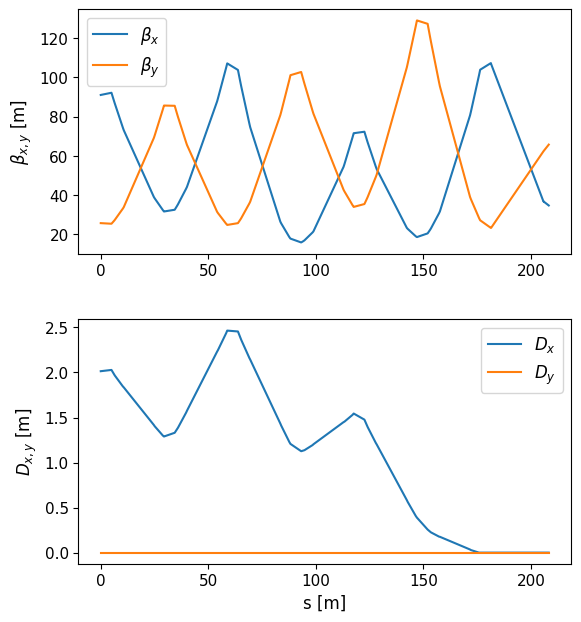

In [7]:
tw_tr=line_tr.twiss(method='4d',  
            start='quad_f',
            end='marker_end', 
            init=tw_init_FODO)
plot_twiss(tw_tr)
tw_init_tr = tw_tr.get_twiss_init('marker_end')

Creating the full arc and checking the closure of the RCS and total circumference

Repetition found in `element_names` -> renaming


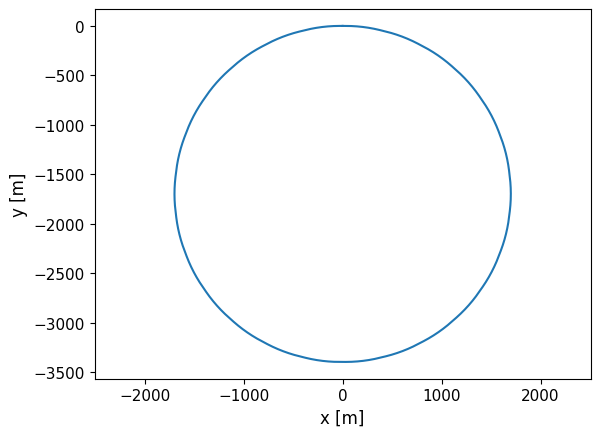

SURVEY RESULTS
X final -1.929965997348174e-11
Z final 2.652988939644274e-12
s total 10674.064144140146
Circumference 10700
Theta/2pi final -1.0000000000000002


In [8]:
tr=arc_el[2:]
tot_arc_el=tr[::-1]+arc_el
tr_name=arc_names[2:]
tot_arc_names=tr_name[::-1]+arc_names
line_tot=xt.Line(elements=tot_arc_el*rcs.nb_arc, element_names=tot_arc_names*rcs.nb_arc)
line_tot.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
line_tot.build_tracker()
survey=line_tot.survey()
plt.figure()
plt.plot(survey['Z'], survey['X'])
plt.axis('equal')
# for i, el in enumerate(line.element_names):
#     if 'dip' in el:
#         plt.axvline(x=survey['Z'][i], color='grey', linestyle='--')
#     elif 'quad' in el:
#         plt.axvline(x=survey['Z'][i], color='red', linestyle='--')
plt.xlabel('x [m]')
plt.ylabel('y [m]')
plt.show()
print('SURVEY RESULTS')
print('X final', survey['X'][-1])
print('Z final', survey['Z'][-1])
print('s total', survey['s'][-1])
print('Circumference', rcs.circumference)
print('Theta/2pi final', survey['theta'][-1]/np.pi/2)

Creating the line of an arc

In [9]:
line_ds=xt.Line(elements=tot_arc_el, element_names=tot_arc_names)
line_ds.particle_ref = xp.Particles(p0c=rcs.injection_energy+(rcs.extraction_energy-rcs.injection_energy)*time, q0=1, mass0=xp.MUON_MASS_EV)
tab_ds=line_ds.get_table()

Repetition found in `element_names` -> renaming


In [10]:
line_ds.element_names

['marker_end',
 'quad_d_half',
 'RF_acc',
 'cavity',
 'drift_ins',
 'drift_ext',
 'quad_f',
 'drift_ext_1',
 'drift_dd',
 'BSC',
 'drift_dd_1',
 'BNC',
 'drift_dd_2',
 'BSC_1',
 'drift_dd_3',
 'drift_ext_2',
 'sxt_d',
 'quad_d',
 'drift_ext_3',
 'drift_dd_4',
 'BSC_2',
 'drift_dd_5',
 'BNC_1',
 'drift_dd_6',
 'BSC_3',
 'drift_dd_7',
 'drift_ext_4',
 'sxt_f',
 'quad_f_1',
 'drift_ext_5',
 'drift_dd_8',
 'BSC_4',
 'drift_dd_9',
 'BNC_2',
 'drift_dd_10',
 'BSC_5',
 'drift_dd_11',
 'drift_ext_6',
 'sxt_d_1',
 'quad_d_1',
 'drift_ext_7',
 'drift_dd_12',
 'BSC_6',
 'drift_dd_13',
 'BNC_3',
 'drift_dd_14',
 'BSC_7',
 'drift_dd_15',
 'drift_ext_8',
 'sxt_f_1',
 'quad_f_2',
 'drift_ext_9',
 'drift_dd_16',
 'BSC_8',
 'drift_dd_17',
 'BNC_4',
 'drift_dd_18',
 'BSC_9',
 'drift_dd_19',
 'drift_ext_10',
 'sxt_d_2',
 'quad_d_2',
 'drift_ext_11',
 'drift_dd_20',
 'BSC_10',
 'drift_dd_21',
 'BNC_5',
 'drift_dd_22',
 'BSC_11',
 'drift_dd_23',
 'drift_ext_12',
 'quad_f_3',
 'sxt_f_2',
 'drift_ext_13',
 '

Matching the dispersion suppressor on the arc from the transfer line results

In [11]:
line_ds.vars['kf1'] = line_tr['quad_f_2'].k1
line_ds.vars['kd1'] = line_tr['quad_d_2'].k1
line_ds.vars['kf2'] = line_tr['quad_f_1'].k1
line_ds.vars['kd2'] = line_tr['quad_d_1'].k1
line_ds.vars['kf3'] = line_tr['quad_f'].k1

line_ds.element_refs['quad_f_5'].k1 = line_ds.vars['kf1']
# line_ds.element_refs['quad_f_1'].k1 = line_ds.vars['kf1']
line_ds.element_refs['quad_f_4'].k1 = line_ds.vars['kf2']
# line_ds.element_refs['quad_f_2'].k1 = line_ds.vars['kf2']
line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf3']
# line_ds.element_refs['quad_f_3'].k1 = line_ds.vars['kf3']

line_ds.element_refs['quad_d_5'].k1 = line_ds.vars['kd1']
# line_ds.element_refs['quad_d'].k1 = line_ds.vars['kd1']
line_ds.element_refs['quad_d_4'].k1 = line_ds.vars['kd2']
# line_ds.element_refs['quad_d_1'].k1 = line_ds.vars['kd2']

match_ds=line_ds.match(
                vary=xt.VaryList(['kf1','kd1','kd2','kf2','kf3'], 
                                step=1e-8,
                                tag='quad'),
                targets=[
                    xt.TargetSet(dx=0, at='marker_end',tol=1e-9),
                        ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=True
                )
# match_ds.step(100)
print('RESULTS FROM DS MATCHING')
match_ds.target_status()
match_ds.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)

Matching: model call n. 21               

RESULTS FROM DS MATCHING
Target status:                           
id state tag tol_met     residue current_val target_val description                                 
 0 ON           True 1.57103e-10 1.57103e-10          0 ('dx', 'marker_end'), val=0, tol=1e-09,  ...
Vary status:                 
id state tag  met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    quad OK  kf1  None          0.0108042 None            0.0106369 1e-08      1
 1 ON    quad OK  kd1  None        -0.00883396 None          -0.00884939 1e-08      1
 2 ON    quad OK  kd2  None        -0.00840565 None          -0.00842835 1e-08      1
 3 ON    quad OK  kf2  None         0.00929994 None            0.0094185 1e-08      1
 4 ON    quad OK  kf3  None         0.00820075 None           0.00833875 1e-08      1


Matching: model call n. 12               

RESULTS FROM TR MATCHING
Target status:                           
id state tag    tol_met      residue current_val target_val description                             
 0 ON    chroma    True -6.99827e-09    0.192308   0.192308 'dqx', val=0.192308, tol=1e-06, weight=1
 1 ON    chroma    True  2.79707e-12    0.192308   0.192308 'dqy', val=0.192308, tol=1e-06, weight=1
Vary status:                 
id state tag met name lower_limit current_val upper_limit val_at_iter_0  step weight
 0 ON    sxt OK  sf   None           0.044929 None            0.0368715 1e-06      1
 1 ON    sxt OK  sd   None         -0.0738093 None            0.0383853 1e-06      1


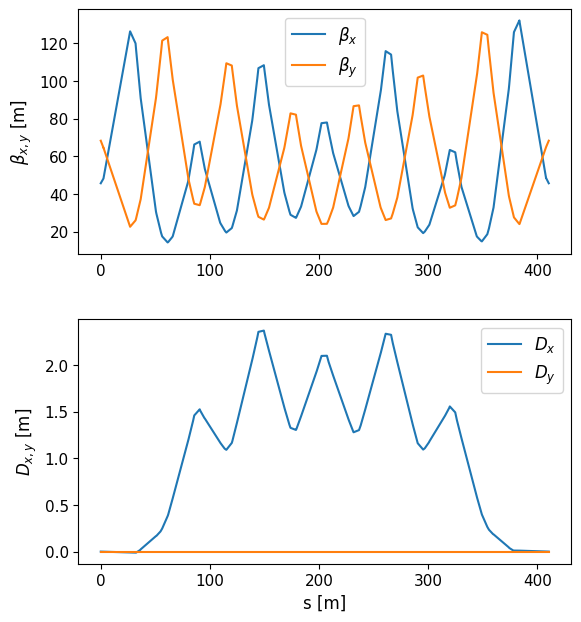

In [12]:
line_ds.vars['sf'] = line_ds['quad_f_1'].k1*line_ds['quad_f_1'].length/tw_ds['dx','quad_f_1']/line_ds['sxt_f'].length
line_ds.vars['sd'] = -line_ds['quad_d_1'].k1*line_ds['quad_d_1'].length/tw_ds['dx','quad_d_1']/line_ds['sxt_d'].length

for sxt in tab_ds.rows[tab_ds.element_type=='Sextupole'].name:
    if 'sxt_d' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sd']
    elif 'sxt_f' in sxt:
        line_ds.element_refs[sxt].k2 = line_ds.vars['sf']
    
chroma_goal=5/rcs.nb_arc

match_ds_chroma=line_ds.match(
                vary=xt.VaryList(['sf','sd'], 
                                step=1e-6,
                                tag='sxt'),
                targets=[
                    xt.TargetSet(dqx=chroma_goal, dqy=chroma_goal, tol=1e-6, tag='chroma')
                    ],
                method='6d',
                matrix_stability_tol=0.05,
                solve=True
                )
print('RESULTS FROM TR MATCHING')
match_ds_chroma.target_status()
match_ds_chroma.vary_status()

tw_ds=line_ds.twiss(method='6d', matrix_stability_tol=0.05)
plot_twiss(tw_ds)

Printing some global parameters: dipole lengths, dipole aperture, qp aperture, path length difference ....

In [13]:
tab=line_ds.get_table()
quad_k1=[]
sxt_k2=[]
for quad in tab.rows[tab.element_type == 'Quadrupole'].name:
    print(quad, line_ds[quad].k1)
    quad_k1.append(line_ds[quad].k1)
for sxt in tab.rows[tab.element_type == 'Sextupole'].name:
    print(sxt, line_ds[sxt].k2)
    sxt_k2.append(line_ds[sxt].k2)
print(max(np.absolute(quad_k1)), max(np.absolute(sxt_k2)))

quad_d_half -0.008833366374245501
quad_f 0.008833366374245501
quad_d -0.008833955908949961
quad_f_1 0.010804199481981877
quad_d_1 -0.008405654750097821
quad_f_2 0.009299942651700097
quad_d_2 -0.008833366374245501
quad_f_3 0.008200752401478544
quad_d_3 -0.008833366374245501
quad_f_4 0.009299942651700097
quad_d_4 -0.008405654750097821
quad_f_5 0.010804199481981877
quad_d_5 -0.008833955908949961
quad_f_6 0.008833366374245501
quad_d_half_1 -0.008833366374245501
sxt_d -0.07380932329128687
sxt_f 0.04492895957858291
sxt_d_1 -0.07380932329128687
sxt_f_1 0.04492895957858291
sxt_d_2 -0.07380932329128687
sxt_f_2 0.04492895957858291
sxt_d_3 -0.07380932329128687
sxt_f_3 0.04492895957858291
sxt_d_4 -0.07380932329128687
sxt_f_4 0.04492895957858291
sxt_d_5 -0.07380932329128687
0.010804199481981877 0.07380932329128687


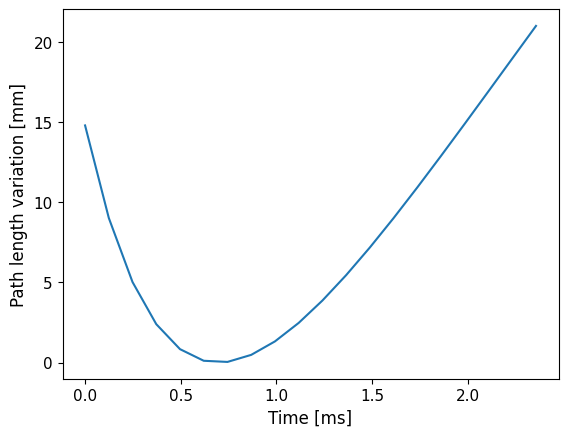

GLOBAL PARAMETER
C 10700
NB arc 26
Nb of cells per arc 6.0
Cell length 64.27182051282051
Longueur totale NC 4366.270034613346
Longueur totale SC 2357.7857952942327
FF arc 0.937
Dipole FF 0.628
MCF 0.000735
Qs 0.286
Qx 41.601
Qy 35.897
dqx 5.0
dqy 5.0
pattern ['BSC', 'BNC', 'BSC']
Max path length diff 21.0 mm
Relative path length diff 1.96 e-6
Traj excursion SC 24.0 mm
Hor apert SC 68.0 mm
Length SC 3.78 m
Traj excursion NC 44.0 mm
Hor apert NC 88.0 mm
Length NC 13.99 m
Horizontal beam size 24.3 mm
Vertical beam size 8.0 mm
Vertical aperture 28.0 mm
Length QP 4.98 m
QP Bpole for 50mm apert 1.35 T
Extra length QP 0.26 m
Length SXT 1.0 m
SXT Bpole for 50mm apert 0.12 T


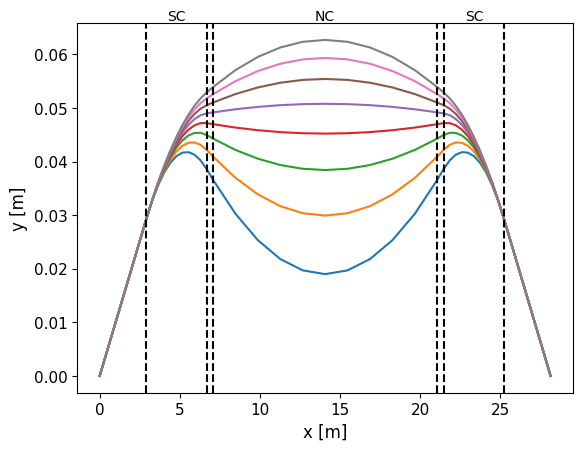

In [14]:
delta = 3.4e-3
max_path_diff=plot_path_diff(rcs, n_turn_rcs)
hor_size_beam=size_beam_diam_hor(tw_ds, rcs,delta)
vert_size_beam=size_beam_diam_vert(tw_ds, rcs,delta)
apert_V=vert_apert(tw_ds, rcs,delta)
print('GLOBAL PARAMETER')
print('C', rcs.circumference)
print('NB arc', rcs.nb_arc)
print('Nb of cells per arc', rcs.nb_cell_arc)
print('Cell length', rcs.cell_length)
print('Longueur totale NC', rcs.dipole_families['BNC']['tot_length'])
if rcs.type == 'hybrid':
    print('Longueur totale SC', rcs.dipole_families['BSC']['tot_length'])
print('FF arc', np.round(rcs.filling_ratio,3))
print('Dipole FF', np.round(rcs.filling_ratio_dipole,3))
print('MCF', round(tw_ds['momentum_compaction_factor'], 6))
print('Qs', round(tw_ds['qs']*rcs.nb_arc, 3))
print('Qx', round(tw_ds['qx']*rcs.nb_arc, 3))
print('Qy', round(tw_ds['qy']*rcs.nb_arc, 3))
print('dqx', round(tw_ds['dqx']*rcs.nb_arc, 2))
print('dqy', round(tw_ds['dqy']*rcs.nb_arc, 2))
print('pattern', rcs.pattern)
if rcs.type == 'hybrid':
    print('Max path length diff', round(max_path_diff*1e3,1), 'mm')
    print('Relative path length diff', round(max_path_diff/rcs.circumference*1e6,2), 'e-6')
    print('Traj excursion SC', round(rcs.width_sc_opt*1e3,0), 'mm')
    print('Hor apert SC', round((rcs.width_sc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
    # print('Apert SC', round(rcs.aperture_sc_opt*1e3,0), 'mm')
    print('Length SC', round(rcs.dipole_families['BSC']['length'],2), 'm')
    print('Traj excursion NC', round(rcs.width_nc_opt*1e3,0), 'mm')
    # print('Apert NC', round(rcs.aperture_nc_opt*1e3,0), 'mm')
    print('Hor apert NC', round((rcs.width_nc_opt+hor_size_beam+2*rcs.dx_qp)*1e3,0), 'mm')
print('Length NC', round(rcs.dipole_families['BNC']['length'],2), 'm')
print('Horizontal beam size', round(hor_size_beam*1e3,1), 'mm')
print('Vertical beam size', round(vert_size_beam*1e3,1), 'mm')
print('Vertical aperture', round(apert_V*1e3,1), 'mm')
print('Length QP', round(line_ds['quad_d'].length,2), 'm')
print('QP Bpole for 50mm apert', round(max(np.absolute(quad_k1))*rcs.ext_Brho*(25e-3),2), 'T')
print('Extra length QP', round(line_ds['drift_ext'].length*2,2), 'm')
print('Length SXT', round(line_ds['sxt_d'].length,2), 'm')
print('SXT Bpole for 50mm apert', round(max(np.absolute(sxt_k2))/2*rcs.ext_Brho*(25e-3)**2,2), 'T')

rcs.plot_traj()

In [15]:
rcs.mcf

np.float64(0.0007283809199908765)

In [16]:
# line_ds.to_json('/mnt/c/muco/code/lattice/RCS3_DS_ext.json')
# para = {  "type": rcs.type,
#    "circumference": rcs.C,
#    "injection_energy": rcs.E_inj,
#    "extraction_energy": rcs.E_ext,
#    "length_short_insertion": rcs.LSSS,
#    "dipole_spacing": rcs.dipole_spacing,
#    "nb_RF_section": rcs.nb_RF_section,
#    "nb_arc": rcs.nb_arc,
#    "nb_cell_arc": rcs.nb_cell_arc,
#    "dipoles": rcs.dipoles,
#    "filling_ratio": rcs.filling_ratio,
#    "filling_ratio_RF": rcs.filling_ratio_RF,
#    "pattern": rcs.pattern
# }
# with open('para_RCS3_opt.json', 'w') as file:
#     json.dump(para, file,indent=4)